
========== PAH PANEL ==========
Samples: 372 | Pathogenic: 310 | Benign: 62
Selected AL features : 164
Total features used : 258
  ExtraTrees: F1=0.7957 | MCC=0.3186 | AUC=0.7551
  RandomForest: F1=0.7932 | MCC=0.2936 | AUC=0.7754

  → Best model: ExtraTrees
Optimal threshold : 0.28

─── Competition Metrics on Hold-out Set ───
  F1 Score            : 0.9231
  MCC                 : 0.4383
  Precision           : 0.8955
  Recall (Sensitivity): 0.9524

                precision    recall  f1-score   support

    Benign (0)       0.62      0.42      0.50        12
Pathogenic (1)       0.90      0.95      0.92        63

      accuracy                           0.87        75
     macro avg       0.76      0.68      0.71        75
  weighted avg       0.85      0.87      0.86        75



<Figure size 300x400 with 0 Axes>

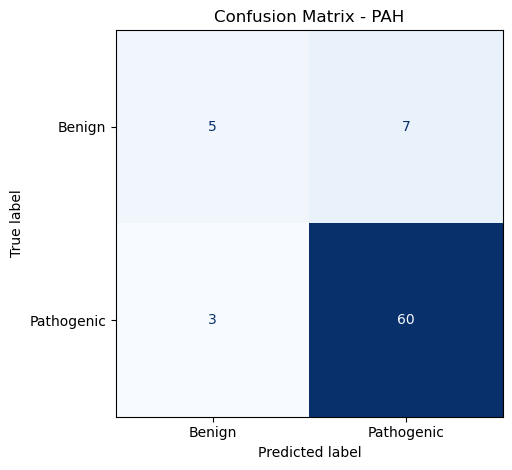

   F1 Score   : 0.9231
   MCC        : 0.4383
   Threshold  : 0.28
   Algorithm  : ExtraTrees
   Features   : 258


In [3]:
# ═══════════════════════════════════════════════════════
# PAH PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (f1_score, matthews_corrcoef, roc_auc_score,
                             classification_report, confusion_matrix, 
                             ConfusionMatrixDisplay)
from imblearn.under_sampling import RandomUnderSampler
import joblib
import warnings
warnings.filterwarnings('ignore')


PAH_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_PAH.csv"   # ← change if needed
PANEL = "PAH"

df = pd.read_csv(PAH_PATH)
y = df['Label']
print(f"\n========== {PANEL} PANEL ==========")
print(f"Samples: {len(df)} | Pathogenic: {(y==1).sum()} | Benign: {(y==0).sum()}")

# ── Feature column groups ──
al_cols  = [c for c in df.columns if c.startswith('AL_')]
ek_cols  = [c for c in df.columns if c.startswith('EK_')]
cat_cols = [c for c in df.columns if c.startswith('CAT_')]
aa_cols  = [c for c in df.columns if c.startswith('AA_')]

# ── Feature builder function ──
def build_features(dataframe, al_to_keep=None):
    feats = pd.DataFrame(index=dataframe.index)
    feats['al_missing_ratio'] = dataframe[al_cols].isna().mean(axis=1)
    al_use = al_to_keep if al_to_keep is not None else al_cols
    feats = pd.concat([feats, dataframe[al_use].fillna(0)], axis=1)
    ek_filled = dataframe[ek_cols].copy()
    for col in ek_cols:
        ek_filled[col] = ek_filled[col].fillna(ek_filled[col].median())
    feats = pd.concat([feats, ek_filled], axis=1)
    cat_encoded = pd.get_dummies(dataframe[cat_cols + aa_cols])
    feats = pd.concat([feats, cat_encoded], axis=1)
    feats = feats.replace([np.inf, -np.inf], np.nan).fillna(0).astype(float)
    return feats

# ── Step 1: Find top AL_ columns ──
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_200 = importances.nlargest(200).index.tolist()
top_al_cols = [c for c in top_200 if c in al_cols]
print(f"Selected AL features : {len(top_al_cols)}")


# ── Step 2: Build feature matrix ──
X = build_features(df, al_to_keep=top_al_cols)
print(f"Total features used : {X.shape[1]}")

# ── Step 3: Cross-validation with 3 folds ──
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=15,
        min_samples_leaf=3,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=15,
        min_samples_leaf=3,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))
    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")


# ── Step 4: Threshold tuning ──
X_tr2, X_hold, y_tr2, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=99)
X_tr2_bal, y_tr2_bal = RandomUnderSampler(
    random_state=42).fit_resample(X_tr2, y_tr2)

best_clf = models[best_name]
best_clf.fit(X_tr2_bal, y_tr2_bal)
probs = best_clf.predict_proba(X_hold)[:, 1]

best_thresh, best_f1 = 0.5, 0.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    score = f1_score(y_hold, preds_t, pos_label=1)
    if score > best_f1:
        best_f1, best_thresh = score, t

print(f"Optimal threshold : {best_thresh:.2f}")
y_final = (probs >= best_thresh).astype(int)


tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()
print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print()
print(classification_report(y_hold, y_final,
      target_names=['Benign (0)', 'Pathogenic (1)']))

# ── Plot: Confusion Matrix ──
plt.figure(figsize=(3,4))

cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(
    cm,
    display_labels=['Benign', 'Pathogenic']
).plot(cmap='Blues', colorbar=False)

plt.title(f'Confusion Matrix - {PANEL}')
plt.tight_layout()
plt.show()

''''# ── Save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)
joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   F1 Score   : {best_f1:.4f}")
print(f"   MCC        : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")

In [7]:
### top 200 is the best


========== PAH PANEL ==========
Samples: 372 | Pathogenic: 310 | Benign: 62
Selected AL features : 133
Total features used : 227
  ExtraTrees: F1=0.7769 | MCC=0.3036 | AUC=0.7579
  RandomForest: F1=0.7804 | MCC=0.2891 | AUC=0.7745

  → Best model: RandomForest
Optimal threshold : 0.29

─── Competition Metrics on Hold-out Set ───
  F1 Score            : 0.9147
  MCC                 : 0.3984
  Precision           : 0.8939
  Recall (Sensitivity): 0.9365



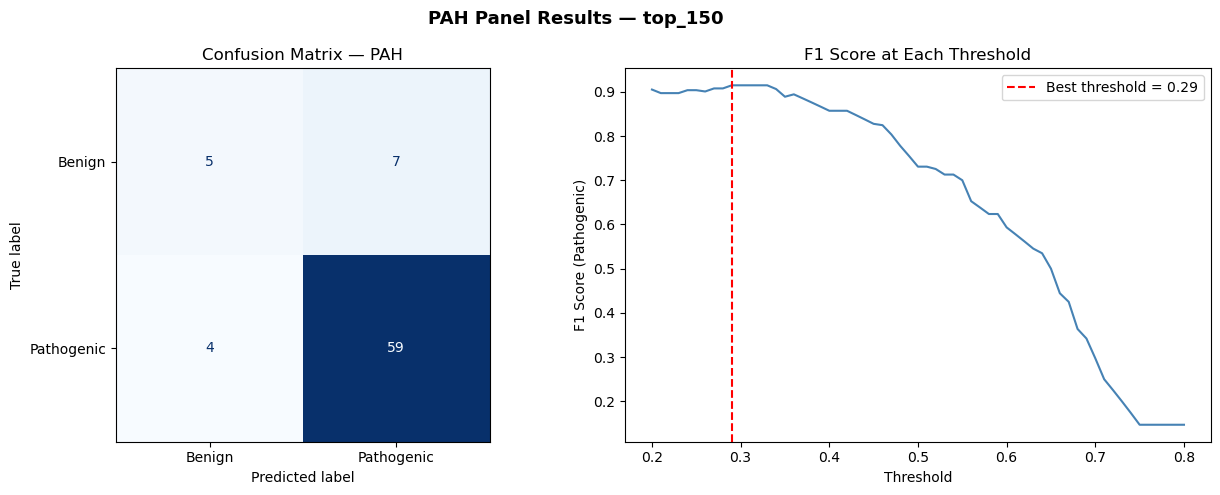

   F1 Score   : 0.9147
   MCC        : 0.3984
   Threshold  : 0.29
   Algorithm  : RandomForest
   Features   : 227


In [4]:
# ═══════════════════════════════════════════════════════
# PAH PANEL — Final Model Training
# ═══════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (f1_score, matthews_corrcoef, roc_auc_score,
                             classification_report, confusion_matrix, 
                             ConfusionMatrixDisplay)
from imblearn.under_sampling import RandomUnderSampler
import joblib
import warnings
warnings.filterwarnings('ignore')


PAH_PATH = r"C:\Users\Sedra\Downloads\YARISMA_TRAIN_PAH.csv"   # ← change if needed
PANEL = "PAH"

df = pd.read_csv(PAH_PATH)
y = df['Label']
print(f"\n========== {PANEL} PANEL ==========")
print(f"Samples: {len(df)} | Pathogenic: {(y==1).sum()} | Benign: {(y==0).sum()}")

# ── Feature column groups ──
al_cols  = [c for c in df.columns if c.startswith('AL_')]
ek_cols  = [c for c in df.columns if c.startswith('EK_')]
cat_cols = [c for c in df.columns if c.startswith('CAT_')]
aa_cols  = [c for c in df.columns if c.startswith('AA_')]

# ── Feature builder function ──
def build_features(dataframe, al_to_keep=None):
    feats = pd.DataFrame(index=dataframe.index)
    feats['al_missing_ratio'] = dataframe[al_cols].isna().mean(axis=1)
    al_use = al_to_keep if al_to_keep is not None else al_cols
    feats = pd.concat([feats, dataframe[al_use].fillna(0)], axis=1)
    ek_filled = dataframe[ek_cols].copy()
    for col in ek_cols:
        ek_filled[col] = ek_filled[col].fillna(ek_filled[col].median())
    feats = pd.concat([feats, ek_filled], axis=1)
    cat_encoded = pd.get_dummies(dataframe[cat_cols + aa_cols])
    feats = pd.concat([feats, cat_encoded], axis=1)
    feats = feats.replace([np.inf, -np.inf], np.nan).fillna(0).astype(float)
    return feats

# ── Step 1: Find top AL_ columns ──
X_full = build_features(df)
X_bal_sel, y_bal_sel = RandomUnderSampler(random_state=42).fit_resample(X_full, y)
quick_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
quick_rf.fit(X_bal_sel, y_bal_sel)
importances = pd.Series(quick_rf.feature_importances_, index=X_full.columns)
top_150 = importances.nlargest(150).index.tolist()
top_al_cols = [c for c in top_150 if c in al_cols]
print(f"Selected AL features : {len(top_al_cols)}")


# ── Step 2: Build feature matrix ──
X = build_features(df, al_to_keep=top_al_cols)
print(f"Total features used : {X.shape[1]}")

# ── Step 3: Cross-validation with 3 folds ──
models = {
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, max_depth=15,
        min_samples_leaf=3,
        class_weight='balanced', random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=15,
        min_samples_leaf=3,
        class_weight='balanced', random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = {}

for name, clf in models.items():
    f1s, mccs, aucs = [], [], []
    for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tr_bal, y_tr_bal = RandomUnderSampler(
            random_state=fold).fit_resample(X_tr, y_tr)
        clf.fit(X_tr_bal, y_tr_bal)
        y_pred = clf.predict(X_val)
        y_prob = clf.predict_proba(X_val)[:, 1]
        f1s.append(f1_score(y_val, y_pred, pos_label=1))
        mccs.append(matthews_corrcoef(y_val, y_pred))
        aucs.append(roc_auc_score(y_val, y_prob))
    results[name] = {
        'F1': np.mean(f1s), 'MCC': np.mean(mccs), 'AUC': np.mean(aucs)}
    print(f"  {name}: F1={results[name]['F1']:.4f} | "
          f"MCC={results[name]['MCC']:.4f} | AUC={results[name]['AUC']:.4f}")

best_name = max(results, key=lambda k: results[k]['F1'])
print(f"\n  → Best model: {best_name}")


# ── Step 4: Threshold tuning ──
X_tr2, X_hold, y_tr2, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=99)
X_tr2_bal, y_tr2_bal = RandomUnderSampler(
    random_state=42).fit_resample(X_tr2, y_tr2)

best_clf = models[best_name]
best_clf.fit(X_tr2_bal, y_tr2_bal)
probs = best_clf.predict_proba(X_hold)[:, 1]

best_thresh, best_f1 = 0.5, 0.0
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    score = f1_score(y_hold, preds_t, pos_label=1)
    if score > best_f1:
        best_f1, best_thresh = score, t

print(f"Optimal threshold : {best_thresh:.2f}")
y_final = (probs >= best_thresh).astype(int)


tn, fp, fn, tp = confusion_matrix(y_hold, y_final).ravel()
print("\n─── Competition Metrics on Hold-out Set ───")
print(f"  F1 Score            : {f1_score(y_hold, y_final, pos_label=1):.4f}")
print(f"  MCC                 : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"  Precision           : {tp/(tp+fp):.4f}")
print(f"  Recall (Sensitivity): {tp/(tp+fn):.4f}")
print()

# ── Plots ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_hold, y_final)
ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Pathogenic']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {PANEL}')
f1_by_thresh = []
for t in np.arange(0.20, 0.80, 0.01):
    preds_t = (probs >= t).astype(int)
    f1_by_thresh.append(f1_score(y_hold, preds_t, pos_label=1))
axes[1].plot(np.arange(0.20, 0.80, 0.01), f1_by_thresh, color='steelblue')
axes[1].axvline(x=best_thresh, color='red', linestyle='--',
                label=f'Best threshold = {best_thresh:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score (Pathogenic)')
axes[1].set_title('F1 Score at Each Threshold')
axes[1].legend()
plt.suptitle(f'{PANEL} Panel Results — top_150', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

''''# ── Save ──
X_bal_final, y_bal_final = RandomUnderSampler(
    random_state=42).fit_resample(X, y)
best_clf.fit(X_bal_final, y_bal_final)
joblib.dump({
    'model': best_clf,
    'feature_cols': list(X.columns),
    'al_cols_used': top_al_cols,
    'threshold': best_thresh,
    'panel': PANEL
}, f'{PANEL}_model.pkl')

print(f"\n✅ {PANEL} model saved as {PANEL}_model.pkl")'''
print(f"   F1 Score   : {best_f1:.4f}")
print(f"   MCC        : {matthews_corrcoef(y_hold, y_final):.4f}")
print(f"   Threshold  : {best_thresh:.2f}")
print(f"   Algorithm  : {best_name}")
print(f"   Features   : {X.shape[1]}")